# NN_L4_fmnist_curves

**Training and validation cross-entropy and validation accuracy by epoch of softmax regression, MLP and CNN on Fashion-MNIST (seed 20261108).**

Neural Networks and Deep Learning (NN), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L4/NN_L4_fmnist_curves/NN_L4_fmnist_curves.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Learning curves of the three models of the lecture (AdamW, batch 128, 12 epochs, one-cycle learning rate). Retrain with lectures/L4/analysis_L4.py.

softmax: best validation epoch = 12   [fmnist.softmax.best_epoch]
mlp: best validation epoch = 12   [fmnist.mlp.best_epoch]
cnn: best validation epoch = 11   [fmnist.cnn.best_epoch]


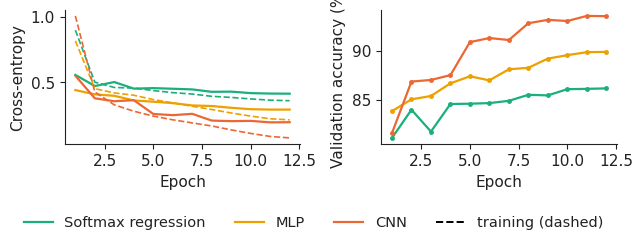

In [3]:
import json, urllib.request
_F = 'fmnist_curves_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L4/NN_L4_fmnist_curves/' + _F))
for k in ['softmax', 'mlp', 'cnn']:
    show(f'fmnist.{k}.best_epoch', f'{k}: best validation epoch', int(np.argmax(R[k]['valid_acc']) + 1))
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.5)); ep = np.arange(1, 13)
for k, c, l in [('softmax', PAL['benchmark'], 'Softmax regression'), ('mlp', PAL['alt'], 'MLP'), ('cnn', PAL['model'], 'CNN')]:
    axes[0].plot(ep, R[k]['train_loss'], color=c, ls='--', lw=1.2); axes[0].plot(ep, R[k]['valid_loss'], color=c, lw=1.6, label=l)
    axes[1].plot(ep, 100 * np.array(R[k]['valid_acc']), color=c, lw=1.6, marker='o', ms=2.5)
axes[0].set_ylabel('Cross-entropy'); axes[1].set_ylabel('Validation accuracy (%)')
for ax in axes: ax.set_xlabel('Epoch')
axes[0].plot([], [], color='k', ls='--', label='training (dashed)')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.15, 1, 1))
fig.savefig('fmnist_curves.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()